# Customer Churn Prediction

## Phase 1: Data Exploration

**Objective:** Understand customer data and identify patterns related to customer churn.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!") 

All libraries imported successfully!


In [2]:
df = pd.read_csv("../data/Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("Dataset Shape:", df.shape)

print("Total Rows:", df.shape[0])

print("Total Columns:", df.shape[1])

Dataset Shape: (7043, 21)
Total Rows: 7043
Total Columns: 21


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [6]:
# Check blank values in TotalCharges

blank_values = df["TotalCharges"].str.strip().eq("").sum()

print("Blank values in TotalCharges:", blank_values)

Blank values in TotalCharges: 11


In [7]:
# Check duplicate records

print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [8]:
# Check target variable distribution

print("Churn Distribution:")
print(df["Churn"].value_counts())

print("\nChurn Percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


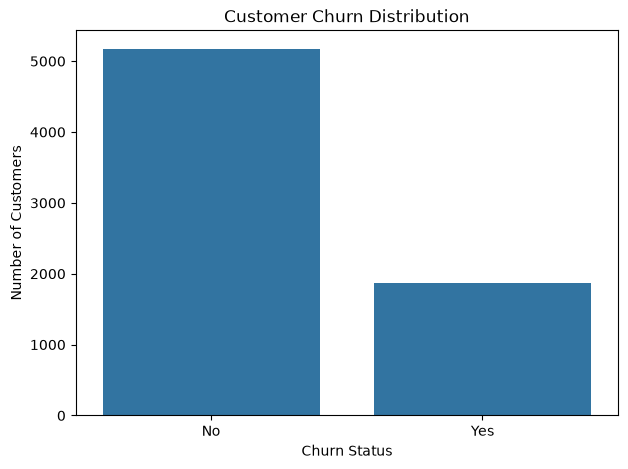

In [9]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

In [10]:

# Convert TotalCharges into numeric format

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Check missing values again
print("Missing values in TotalCharges:",
      df["TotalCharges"].isnull().sum())

# Inspect rows containing missing values
df[df["TotalCharges"].isnull()][
    ["tenure", "MonthlyCharges", "TotalCharges"]
]


Missing values in TotalCharges: 11


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [11]:

# Fill missing TotalCharges with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Verify missing values
print("Missing values after cleaning:",
      df["TotalCharges"].isnull().sum())

# Check updated records
df[df["tenure"] == 0][
    ["tenure", "MonthlyCharges", "TotalCharges"]
]


Missing values after cleaning: 0


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,0.0
753,0,20.25,0.0
936,0,80.85,0.0
1082,0,25.75,0.0
1340,0,56.05,0.0
3331,0,19.85,0.0
3826,0,25.35,0.0
4380,0,20.00,0.0
5218,0,19.70,0.0
6670,0,73.35,0.0


In [12]:

# Select numerical columns
numerical_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# Statistical summary
df[numerical_cols].describe()


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


In [13]:

# Select numerical columns
numerical_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# Statistical summary
df[numerical_cols].describe()


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


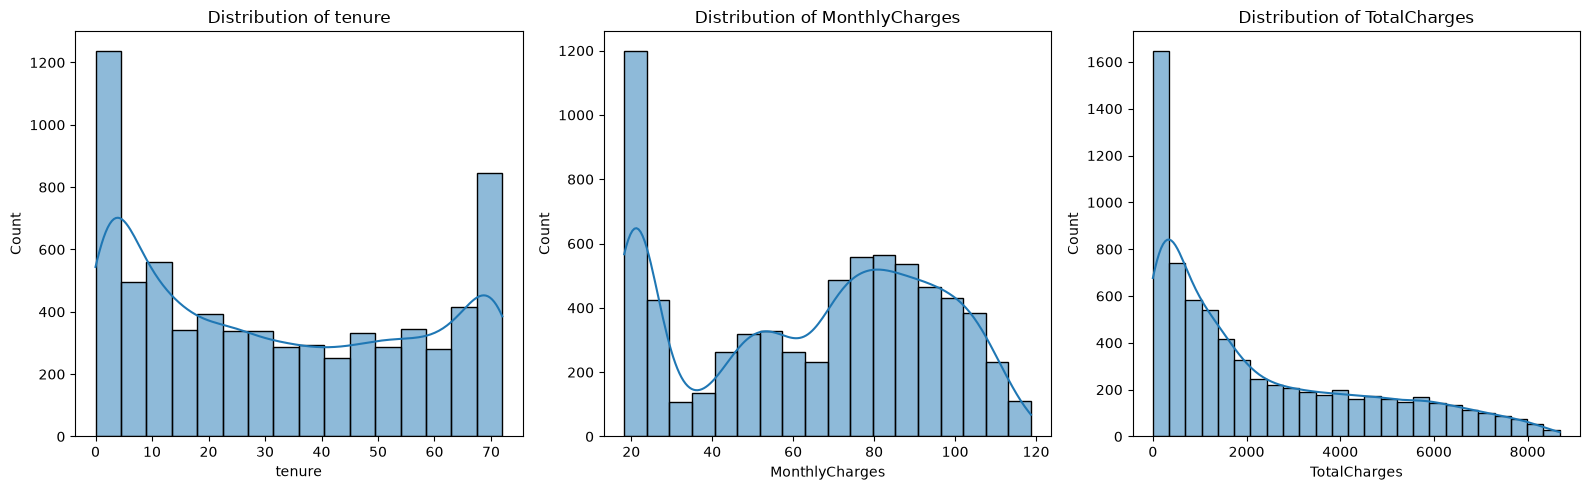

In [14]:

# Visualize numerical feature distributions

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, col in enumerate(numerical_cols):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()


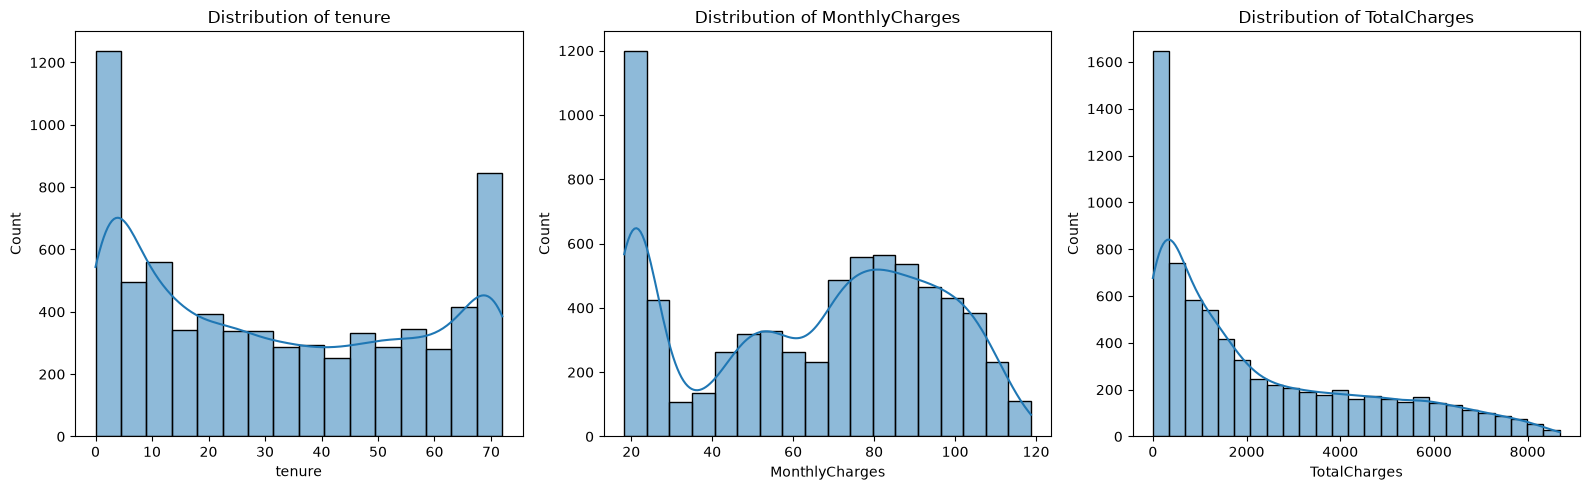

In [15]:

# Visualize numerical feature distributions

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, col in enumerate(numerical_cols):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()


In [16]:

# Identify categorical columns

categorical_cols = df.select_dtypes(
    include="object"
).columns.tolist()

# Remove customerID from analysis
categorical_cols.remove("customerID")

print("Categorical Columns:")
print(categorical_cols)

print("\nTotal Categorical Features:",
      len(categorical_cols))


Categorical Columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']

Total Categorical Features: 16


C:\Users\singh\AppData\Local\Temp\ipykernel_17952\3787280079.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(


In [17]:

# Analyze categorical feature distributions

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())



--- gender ---
gender
Male      3555
Female    3488
Name: count, dtype: int64

--- Partner ---
Partner
No     3641
Yes    3402
Name: count, dtype: int64

--- Dependents ---
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

--- PhoneService ---
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

--- MultipleLines ---
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

--- InternetService ---
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

--- OnlineSecurity ---
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

--- OnlineBackup ---
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

--- DeviceProtection ---
DeviceProtection
No                     3095
Yes                    2422
No internet service   

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


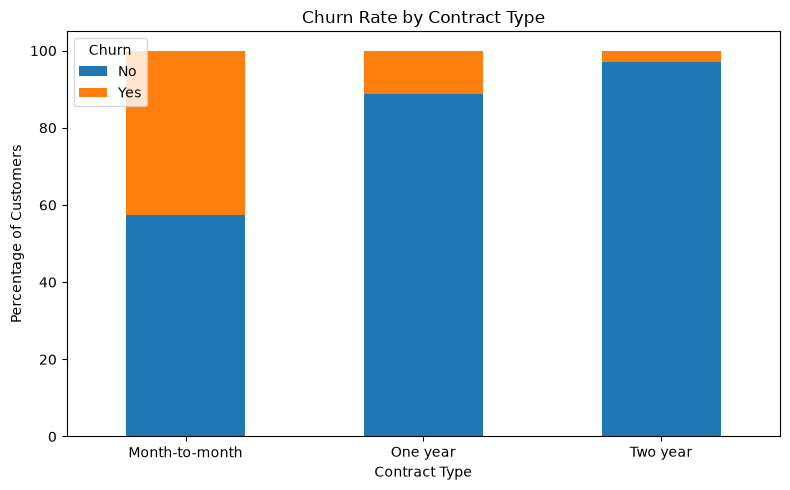

In [18]:

# Analyze Contract Type vs Customer Churn

churn_by_contract = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(churn_by_contract)

# Visualize churn percentage
churn_by_contract.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Churn                   No        Yes
InternetService                      
DSL              81.040892  18.959108
Fiber optic      58.107235  41.892765
No               92.595020   7.404980


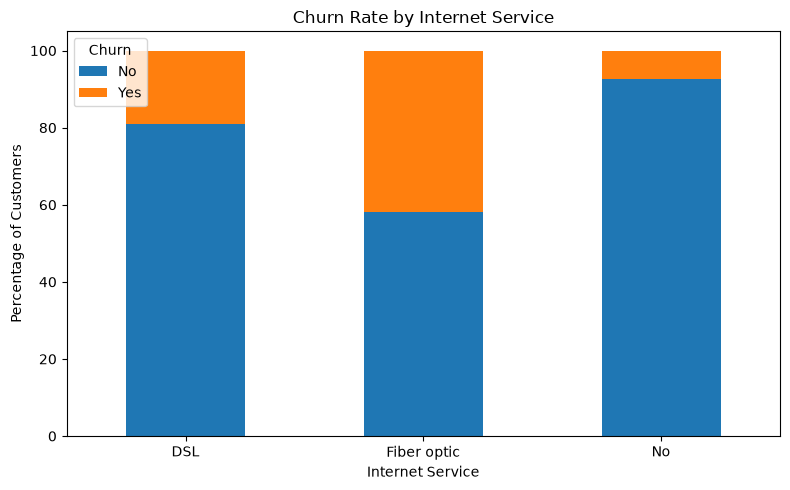

In [19]:

# Analyze Internet Service vs Customer Churn

churn_by_internet = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(churn_by_internet)

# Visualize churn percentage

churn_by_internet.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700


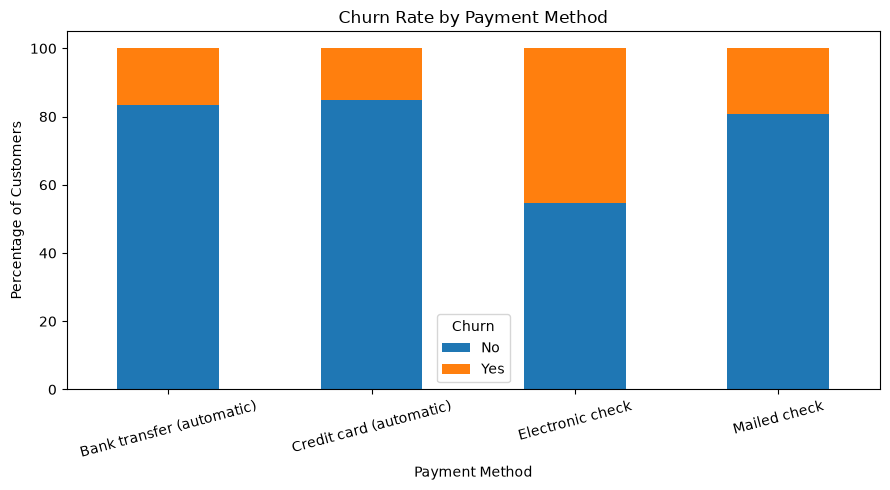

In [20]:

# Analyze Payment Method vs Customer Churn

churn_by_payment = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(churn_by_payment)

# Visualize churn percentage

churn_by_payment.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


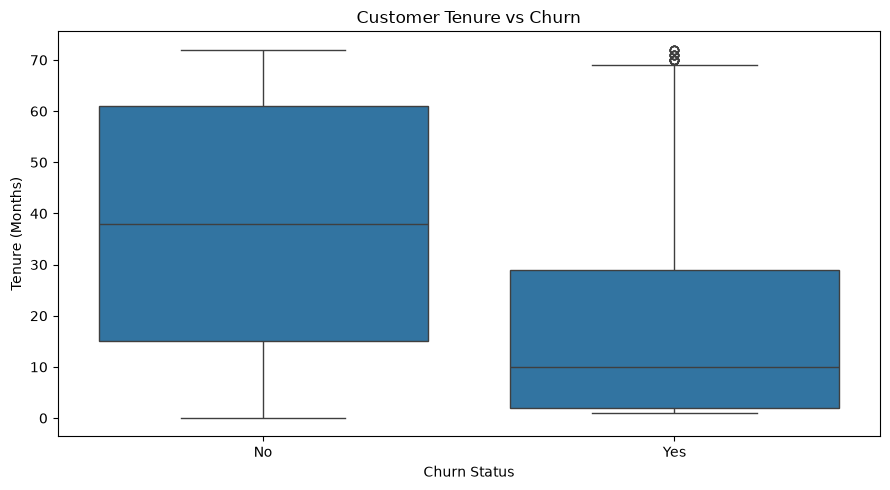

In [21]:

# Analyze Tenure vs Customer Churn

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")

plt.tight_layout()
plt.show()


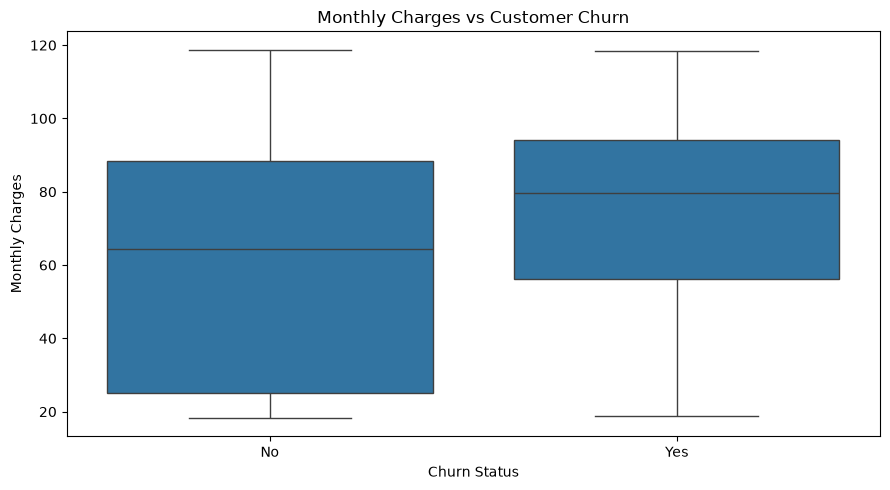

In [22]:

# Analyze Monthly Charges vs Customer Churn

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()


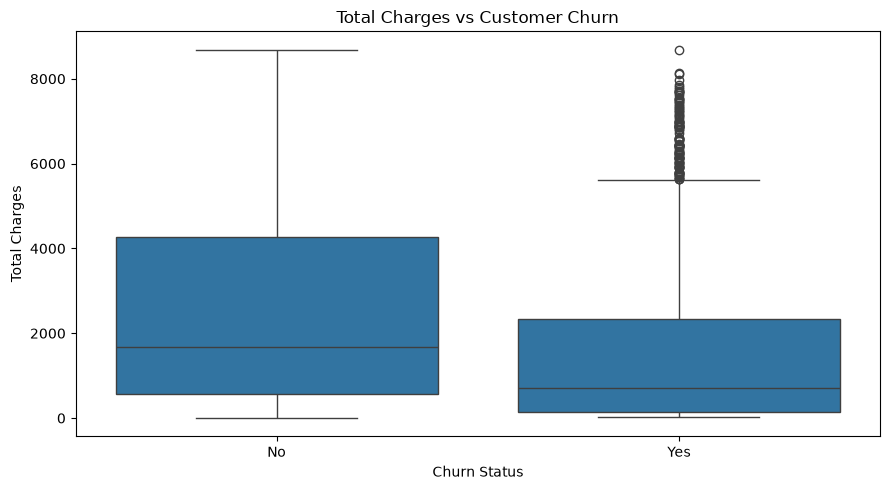

In [23]:

# Analyze Total Charges vs Customer Churn

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="TotalCharges"
)

plt.title("Total Charges vs Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Total Charges")

plt.tight_layout()
plt.show()


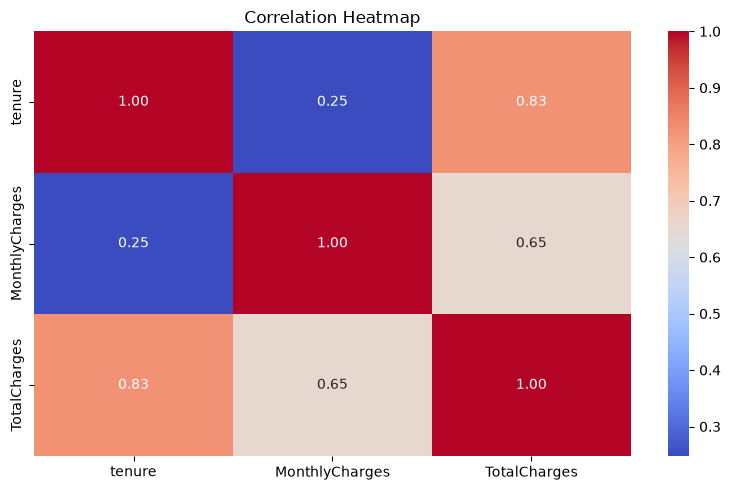

In [24]:

# Correlation Analysis

correlation = df[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].corr()

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()



## Phase 1: Exploratory Data Analysis Summary

### Key Findings

1. Dataset contains 7,043 customer records and 21 columns.
2. No duplicate records were found.
3. 11 missing values were identified in TotalCharges and handled.
4. Approximately 26.54% of customers have churned.
5. Month-to-month contract customers show the highest churn rate.
6. Fiber optic users have a higher churn rate than DSL users.
7. Electronic check users show a comparatively higher churn rate.
8. Customers with shorter tenure are more likely to churn.
9. Tenure and TotalCharges have a strong positive correlation (0.83).


## Phase 2: Data Preprocessing

### Step 1: Remove Unnecessary Columns

The customerID column is a unique identifier and does not provide meaningful predictive information. Therefore, we will remove it before model training.

In [25]:

# Remove customerID column

df.drop(columns=["customerID"], inplace=True)

# Verify updated dataset

print("Updated Dataset Shape:", df.shape)
print("\nRemaining Columns:")
print(df.columns.tolist())


Updated Dataset Shape: (7043, 20)

Remaining Columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


C:\Users\singh\AppData\Local\Temp\ipykernel_17952\2584595633.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["customerID"], inplace=True)


In [ ]:

### Step 2: Separate Features and Target Variable

We separate the input features (X) from the target variable (y).

- X contains customer information used for prediction.
- y contains the actual Churn status (Yes/No).


In [26]:

# Separate features and target variable

X = df.drop(columns=["Churn"])
y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Verify the separation

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())


Features Shape: (7043, 19)
Target Shape: (7043,)

Target Distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64



### Step 3: Identify Numerical and Categorical Features

We identify numerical and categorical features separately because they require different preprocessing techniques.

- Numerical features contain measurable values.
- Categorical features represent groups or categories.


In [27]:

# Identify numerical and categorical features

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nTotal Numerical Features:", len(numerical_features))
print("Total Categorical Features:", len(categorical_features))


Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Total Numerical Features: 4
Total Categorical Features: 15


C:\Users\singh\AppData\Local\Temp\ipykernel_17952\2446107237.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [28]:
# Check unique categories in categorical features

for col in categorical_features:
    print(f"\n{col}:")
    print(df[col].unique())


gender:
<StringArray>
['Female', 'Male']
Length: 2, dtype: str

Partner:
<StringArray>
['Yes', 'No']
Length: 2, dtype: str

Dependents:
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

PhoneService:
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

MultipleLines:
<StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str

InternetService:
<StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

OnlineSecurity:
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

OnlineBackup:
<StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str

DeviceProtection:
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

TechSupport:
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

StreamingTV:
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

StreamingMovies:
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

Contract:
<StringArray>
['Month-to-month', 

In [29]:
from sklearn.preprocessing import OneHotEncoder

# Initialize One-Hot Encoder
encoder = OneHotEncoder(
    drop="first",
    handle_unknown="ignore",
    sparse_output=False
)

# Encode categorical features
encoded_data = encoder.fit_transform(X[categorical_features])

# Convert encoded data into DataFrame
encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(categorical_features),
    index=X.index
)

# Display encoded data
encoded_df.head()

,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
1,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


In [30]:
# Combine numerical and encoded categorical features

X_processed = pd.concat(
    [X[numerical_features], encoded_df],
    axis=1
)

# Verify processed dataset

print("Processed Dataset Shape:", X_processed.shape)

print("\nFirst 5 Rows:")
display(X_processed.head())

print("\nData Types:")
print(X_processed.dtypes.value_counts())

Processed Dataset Shape: (7043, 30)

First 5 Rows:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
1,0,34,56.95,1889.50,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0,2,53.85,108.15,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
3,0,45,42.30,1840.75,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,0,2,70.70,151.65,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0



Data Types:
float64    28
int64       2
Name: count, dtype: int64


In [31]:
from sklearn.model_selection import train_test_split

# Split original features and target
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Verify dataset shapes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Churn Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Churn Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training Features: (5634, 19)
Testing Features: (1409, 19)

Training Target: (5634,)
Testing Target: (1409,)

Training Churn Distribution:
Churn
0    73.464679
1    26.535321
Name: proportion, dtype: float64

Testing Churn Distribution:
Churn
0    73.456352
1    26.543648
Name: proportion, dtype: float64


In [32]:
# Fit encoder only on training data
X_train_encoded = encoder.fit_transform(
    X_train[categorical_features]
)

# Transform testing data using the same encoder
X_test_encoded = encoder.transform(
    X_test[categorical_features]
)

# Convert encoded arrays into DataFrames
X_train_encoded_df = pd.DataFrame(
    X_train_encoded,
    columns=encoder.get_feature_names_out(categorical_features),
    index=X_train.index
)

X_test_encoded_df = pd.DataFrame(
    X_test_encoded,
    columns=encoder.get_feature_names_out(categorical_features),
    index=X_test.index
)

# Combine numerical and encoded categorical features
X_train_processed = pd.concat(
    [X_train[numerical_features], X_train_encoded_df],
    axis=1
)

X_test_processed = pd.concat(
    [X_test[numerical_features], X_test_encoded_df],
    axis=1
)

# Verify
print("Training Shape:", X_train_processed.shape)
print("Testing Shape:", X_test_processed.shape)

Training Shape: (5634, 30)
Testing Shape: (1409, 30)


In [33]:
from sklearn.preprocessing import StandardScaler

# Initialize scaler
scaler = StandardScaler()

# Fit only on training numerical features
X_train_scaled = scaler.fit_transform(
    X_train_processed[numerical_features]
)

# Transform testing numerical features
X_test_scaled = scaler.transform(
    X_test_processed[numerical_features]
)

# Convert back to DataFrames
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=numerical_features,
    index=X_train_processed.index
)

X_test_scaled_df = pd.DataFrame(
    X_test_scaled,
    columns=numerical_features,
    index=X_test_processed.index
)

# Replace original numerical features
X_train_processed[numerical_features] = X_train_scaled_df
X_test_processed[numerical_features] = X_test_scaled_df

print("Training Shape:", X_train_processed.shape)
print("Testing Shape:", X_test_processed.shape)

print("\nScaled Numerical Features:")
print(X_train_processed[numerical_features].describe())

Training Shape: (5634, 30)
Testing Shape: (1409, 30)

Scaled Numerical Features:
       SeniorCitizen        tenure  MonthlyCharges  TotalCharges
count   5.634000e+03  5.634000e+03    5.634000e+03  5.634000e+03
mean    7.440898e-17 -1.008935e-17   -2.402527e-16  2.522338e-17
std     1.000089e+00  1.000089e+00    1.000089e+00  1.000089e+00
min    -4.417730e-01 -1.322329e+00   -1.544028e+00 -1.008922e+00
25%    -4.417730e-01 -9.559779e-01   -9.711977e-01 -8.321009e-01
50%    -4.417730e-01 -1.418632e-01    1.848336e-01 -3.968446e-01
75%    -4.417730e-01  9.164859e-01    8.319124e-01  6.741944e-01
max     2.263606e+00  1.608483e+00    1.785939e+00  2.801869e+00


In [34]:
# Final Dataset Verification

print("===== DATASET SHAPES =====")
print("X_train:", X_train_processed.shape)
print("X_test:", X_test_processed.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# Check missing values
print("\n===== MISSING VALUES =====")
print("Training:", X_train_processed.isnull().sum().sum())
print("Testing:", X_test_processed.isnull().sum().sum())

# Check feature consistency
print("\n===== FEATURE CONSISTENCY =====")
print("Same Columns:",
      list(X_train_processed.columns) ==
      list(X_test_processed.columns))

# Check target distribution
print("\n===== TARGET DISTRIBUTION =====")
print(y_train.value_counts())
print(y_test.value_counts())

===== DATASET SHAPES =====
X_train: (5634, 30)
X_test: (1409, 30)
y_train: (5634,)
y_test: (1409,)

===== MISSING VALUES =====
Training: 0
Testing: 0

===== FEATURE CONSISTENCY =====
Same Columns: True

===== TARGET DISTRIBUTION =====
Churn
0    4139
1    1495
Name: count, dtype: int64
Churn
0    1035
1     374
Name: count, dtype: int64


## Phase 3: Model Training

### Step 1: Logistic Regression

After completing data preprocessing, we are now ready to train our first Machine Learning model.

Logistic Regression is a supervised classification algorithm used to predict categorical outcomes. In this project, it will predict whether a customer is likely to leave the service (Churn) or continue using it (No Churn).

**Objectives:**
1. Initialize the Logistic Regression classifier.
2. Train the model using the training dataset.
3. Predict customer churn on unseen testing data.
4. Evaluate the model's performance using classification metrics.

**Target Variable:**
- 0 – No Churn
- 1 – Churn

We will use Logistic Regression as our baseline model and later compare its performance with other classification algorithms.

In [35]:
from sklearn.linear_model import LogisticRegression

# Initialize Logistic Regression
log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
log_model.fit(X_train_processed, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [36]:
# Predict customer churn on testing data
y_pred = log_model.predict(X_test_processed)

# Display actual and predicted values
print("Actual Values:", y_test.values[:10])
print("Predicted Values:", y_pred[:10])

Actual Values: [0 0 0 0 0 0 0 0 0 1]
Predicted Values: [0 1 0 0 0 1 0 0 0 0]


### Step 2: Model Evaluation – Logistic Regression

After training the Logistic Regression model and generating predictions on the testing dataset, we will now evaluate its performance.

We will use the following evaluation metrics:

1. **Accuracy:** Measures the overall percentage of correct predictions.
2. **Precision:** Measures how many customers predicted as churners actually churned.
3. **Recall:** Measures how many actual churners were correctly identified by the model.
4. **F1-Score:** Represents the harmonic mean of Precision and Recall.
5. **Confusion Matrix:** Shows the number of correct and incorrect predictions.

These metrics will help us understand how effectively our model identifies customers who are likely to leave the service.

In [37]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"]
))

Model Accuracy: 80.69552874378992 %

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.90      0.87      1035
       Churn       0.66      0.56      0.61       374

    accuracy                           0.81      1409
   macro avg       0.76      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



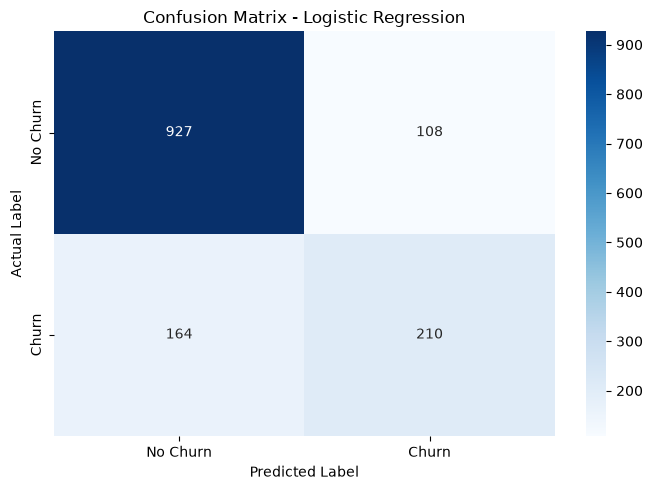

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Visualize confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [39]:
### Step 2: Model Evaluation – Logistic Regression

The Logistic Regression model was evaluated using Accuracy, Precision, Recall, F1-score, and Confusion Matrix.

**Evaluation Results:**

- Accuracy: 80.70%
- Churn Precision: 66%
- Churn Recall: 56%
- Churn F1-score: 61%

**Key Observations:**

1. The model achieved an overall accuracy of approximately 80.70%.
2. It performs better at identifying customers who do not churn.
3. The churn recall of 56% indicates that several actual churn customers are not identified.
4. The confusion matrix shows 164 False Negatives, highlighting scope for improvement.

**Conclusion:**

Logistic Regression provides a reasonable baseline for customer churn prediction. However, further optimization is required to improve churn detection performance.

SyntaxError: invalid syntax (1126632716.py, line 3)

In [ ]:
### Step 3: Decision Tree Classifier

A Decision Tree is a supervised machine learning algorithm used for classification and regression tasks.

It makes predictions by splitting the dataset into smaller subsets based on feature conditions.

For Customer Churn Prediction, the Decision Tree learns patterns such as:

- Does the customer have a month-to-month contract?
- Is the customer using electronic check payment?
- How long has the customer been with the company?

**Objective:**

Train a Decision Tree Classifier to predict customer churn and compare its performance with Logistic Regression.

We will initially use default hyperparameters to establish a baseline performance.

In [40]:
from sklearn.tree import DecisionTreeClassifier

# Initialize Decision Tree Classifier
dt_model = DecisionTreeClassifier(
    random_state=42
)

# Train the model
dt_model.fit(X_train_processed, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [41]:
# Predict customer churn on testing data
y_pred_dt = dt_model.predict(X_test_processed)

# Display actual and predicted values
print("Actual Values:", y_test.values[:10])
print("Predicted Values:", y_pred_dt[:10])

Actual Values: [0 0 0 0 0 0 0 0 0 1]
Predicted Values: [0 1 0 1 0 0 0 0 0 0]


### Step 4: Model Evaluation – Decision Tree

After training the Decision Tree Classifier, we evaluate its performance on the testing dataset.

We will use the following evaluation metrics:

1. **Accuracy:** Measures the overall percentage of correct predictions.
2. **Precision:** Measures how many predicted churn customers actually churned.
3. **Recall:** Measures how many actual churn customers were correctly identified.
4. **F1-score:** Provides a balance between Precision and Recall.
5. **Confusion Matrix:** Shows correct and incorrect predictions across both classes.

**Objective:** Evaluate the Decision Tree model and compare its performance with Logistic Regression.

In [42]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Calculate accuracy
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", accuracy_dt * 100, "%")

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_dt,
    target_names=["No Churn", "Churn"]
))

Decision Tree Accuracy: 72.53371185237756 %

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.81      0.81      0.81      1035
       Churn       0.48      0.48      0.48       374

    accuracy                           0.73      1409
   macro avg       0.65      0.65      0.65      1409
weighted avg       0.72      0.73      0.72      1409



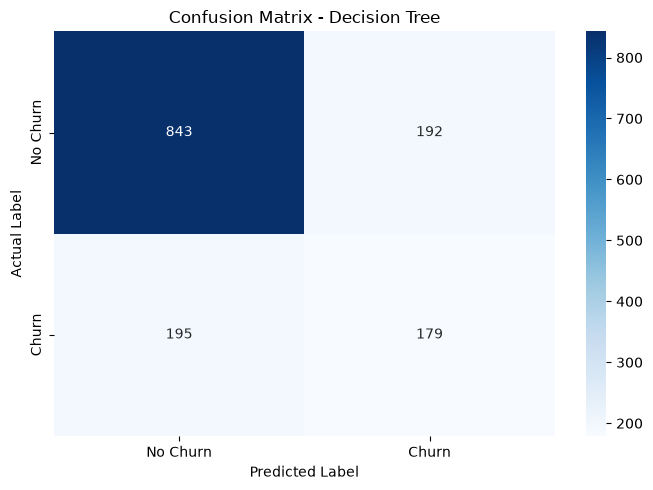

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate confusion matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)

# Plot confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

### Step 5: Model Comparison – Logistic Regression vs Decision Tree

The performance of both models is compared using Accuracy, Precision, Recall, and F1-score.

| Evaluation Metric | Logistic Regression | Decision Tree |
|:------------------|:------------------:|:-------------:|
| Accuracy | 80.70% | 72.53% |
| Churn Precision | 66% | 48% |
| Churn Recall | 56% | 48% |
| Churn F1-score | 61% | 48% |

**Winner: Logistic Regression**

Logistic Regression outperformed Decision Tree across all evaluation metrics. Therefore, it currently provides better performance for customer churn prediction.

---

### Step 6: Confusion Matrix Analysis – Decision Tree

The confusion matrix provides a detailed breakdown of correct and incorrect predictions.

| Actual Class | Predicted No Churn | Predicted Churn |
|:------------:|:------------------:|:---------------:|
| No Churn | 843 (TN) | 192 (FP) |
| Churn | 195 (FN) | 179 (TP) |

**Key Observations:**

1. **True Negatives (843):** Correctly identified customers who did not churn.
2. **False Positives (192):** Predicted churn, but customers did not churn. 
3. **False Negatives (195):** Failed to identify customers who actually churned.
4. **True Positives (179):** Correctly identified customers who churned.

**Conclusion:**

The Decision Tree model produces more False Negatives (195) than Logistic Regression (164). This indicates that Logistic Regression is currently more effective at identifying customers who are likely to churn.

### Step 7: Random Forest Classifier

Random Forest is a supervised machine learning algorithm based on Ensemble Learning.

It creates multiple Decision Trees and combines their predictions using Majority Voting to make the final classification.

**How it works:**

1. Creates multiple Decision Trees using different samples of the training dataset.
2. Each tree makes its own prediction.
3. Combines predictions from all trees.
4. Uses Majority Voting to determine the final prediction.

**Objective:**

Train a Random Forest Classifier to predict customer churn and evaluate whether combining multiple Decision Trees improves prediction performance.

We will initially use default hyperparameters to establish a baseline performance.

In [44]:
from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train_processed, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [45]:
# Predict customer churn on testing data
y_pred_rf = rf_model.predict(X_test_processed)

# Display actual and predicted values
print("Actual Values:", y_test.values[:10])
print("Predicted Values:", y_pred_rf[:10])

Actual Values: [0 0 0 0 0 0 0 0 0 1]
Predicted Values: [0 1 0 0 0 0 0 0 0 0]


### Step 8: Model Evaluation – Random Forest

In this step, we will evaluate the performance of the Random Forest Classifier on unseen testing data.

We will use the following evaluation metrics:

1. **Accuracy:** Measures the overall percentage of correct predictions.
2. **Precision:** Measures how many customers predicted to churn actually churned.
3. **Recall:** Measures how many actual churn customers were correctly identified.
4. **F1-Score:** Provides a balance between Precision and Recall.

We will also generate a Confusion Matrix to analyze correct and incorrect predictions.

**Objective:** Determine how effectively Random Forest identifies customers who are likely to leave the service.

In [46]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Calculate Accuracy
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", accuracy_rf * 100, "%")

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["No Churn", "Churn"]
))

Random Forest Accuracy: 78.49538679914833 %

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.83      0.89      0.86      1035
       Churn       0.62      0.49      0.55       374

    accuracy                           0.78      1409
   macro avg       0.72      0.69      0.70      1409
weighted avg       0.77      0.78      0.78      1409



### Step 8: Model Evaluation – Random Forest

The Random Forest Classifier was evaluated using Accuracy, Precision, Recall, and F1-score on the testing dataset.

| Evaluation Metric | Random Forest |
|:---|---:|
| Accuracy | 78.50% |
| Churn Precision | 62% |
| Churn Recall | 49% |
| Churn F1-score | 55% |

### Step 9: Model Comparison – Logistic Regression vs Decision Tree vs Random Forest

We compare all three models to identify which algorithm performs best for customer churn prediction.

| Evaluation Metric | Logistic Regression | Decision Tree | Random Forest |
|:---|---:|---:|---:|
| Accuracy | 80.70% | 72.53% | 78.50% |
| Churn Precision | 66% | 48% | 62% |
| Churn Recall | 56% | 48% | 49% |
| Churn F1-score | 61% | 48% | 55% |

**Current Best Model: Logistic Regression**

Based on the evaluation results, Logistic Regression currently outperforms both Decision Tree and Random Forest across all four evaluation metrics.

### Key Observations

1. Logistic Regression achieves the highest accuracy (80.70%).
2. Logistic Regression has the highest Churn Precision (66%).
3. Logistic Regression achieves the highest Churn Recall (56%).
4. Logistic Regression also has the highest Churn F1-score (61%).
5. Random Forest performs better than Decision Tree across all four metrics.
6. Random Forest does not outperform Logistic Regression on this dataset.

**Conclusion:**

Logistic Regression is currently our best-performing baseline model. However, we will evaluate additional classification algorithms and perform hyperparameter tuning before selecting the final model.

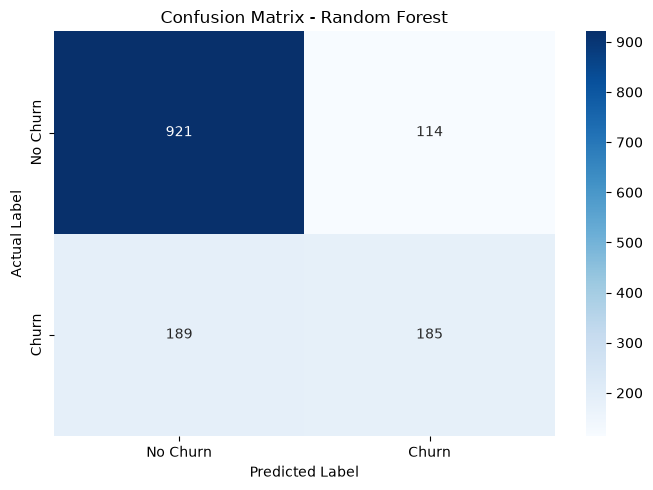

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

# Visualize Confusion Matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

### Step 10: Confusion Matrix Analysis – Random Forest

The Confusion Matrix provides a detailed breakdown of correct and incorrect predictions made by the Random Forest Classifier.

| Actual / Predicted | No Churn | Churn |
|:---|---:|---:|
| Actual No Churn | 921 (TN) | 114 (FP) |
| Actual Churn | 189 (FN) | 185 (TP) |

**Key Observations:**

1. **True Negatives (921):** Correctly identified customers who did not churn.
2. **False Positives (114):** Predicted churn, but customers did not churn.
3. **False Negatives (189):** Failed to identify customers who actually churned.
4. **True Positives (185):** Correctly identified customers who churned.

**Conclusion:**

Random Forest correctly identified 185 out of 374 actual churn customers, achieving approximately 49.5% Churn Recall.

Although the model performs better than Decision Tree, it still misses a significant number of customers who are likely to leave the service.

### Step 11: Model Performance Comparison

In this step, we will compare the performance of Logistic Regression, Decision Tree, and Random Forest using a grouped bar chart.

We will compare four evaluation metrics:

1. Accuracy
2. Precision
3. Recall
4. F1-score

The comparison will help us visually understand the strengths and weaknesses of each classification algorithm.

**Objective:** Identify the best-performing model based on multiple evaluation metrics rather than relying only on accuracy.

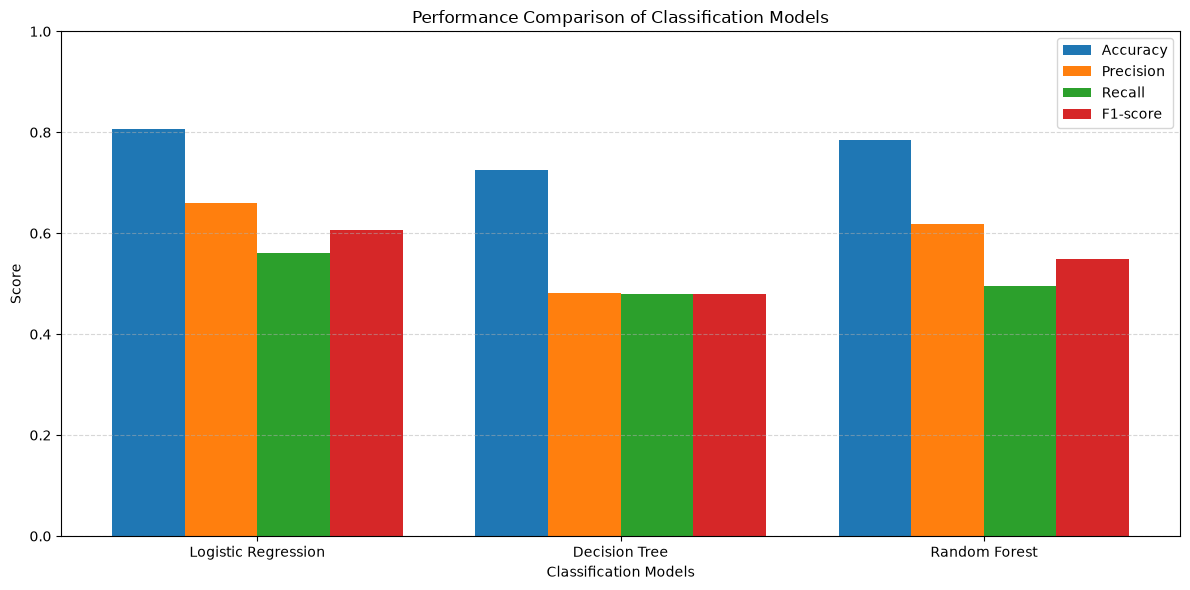

In [48]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

# Model names
models = ["Logistic Regression", "Decision Tree", "Random Forest"]

# Calculate evaluation metrics
accuracy_values = [
    accuracy,
    accuracy_dt,
    accuracy_rf
]

precision_values = [
    precision_score(y_test, y_pred),
    precision_score(y_test, y_pred_dt),
    precision_score(y_test, y_pred_rf)
]

recall_values = [
    recall_score(y_test, y_pred),
    recall_score(y_test, y_pred_dt),
    recall_score(y_test, y_pred_rf)
]

f1_values = [
    f1_score(y_test, y_pred),
    f1_score(y_test, y_pred_dt),
    f1_score(y_test, y_pred_rf)
]

# Create grouped bar chart
x = np.arange(len(models))
width = 0.2

plt.figure(figsize=(12, 6))

plt.bar(x - 1.5 * width, accuracy_values, width, label="Accuracy")
plt.bar(x - 0.5 * width, precision_values, width, label="Precision")
plt.bar(x + 0.5 * width, recall_values, width, label="Recall")
plt.bar(x + 1.5 * width, f1_values, width, label="F1-score")

plt.title("Performance Comparison of Classification Models")
plt.xlabel("Classification Models")
plt.ylabel("Score")
plt.xticks(x, models)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### Step 13: Hyperparameter Tuning

Hyperparameter tuning is the process of finding the best configuration of a machine learning algorithm to improve its performance.

In this step, we will use GridSearchCV to explore different hyperparameter combinations and select the best configuration using 5-fold Cross Validation.

We will perform hyperparameter tuning on:

1. Logistic Regression
2. Random Forest

**Evaluation Metric:** F1-score

**Objective:** Improve model performance by finding suitable hyperparameters while maintaining a balance between Precision and Recall.

In [49]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

# Initialize Logistic Regression
log_model_tuning = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Define hyperparameter grid
log_param_grid = {
    "C": [0.01, 0.1, 1, 10],
    "class_weight": [None, "balanced"]
}

# Apply GridSearchCV
log_grid = GridSearchCV(
    estimator=log_model_tuning,
    param_grid=log_param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

# Train using GridSearchCV
log_grid.fit(X_train_processed, y_train)

# Display best parameters
print("Best Logistic Regression Parameters:")
print(log_grid.best_params_)

print("\nBest Cross-Validation F1-score:")
print(log_grid.best_score_)

Best Logistic Regression Parameters:
{'C': 0.1, 'class_weight': 'balanced'}

Best Cross-Validation F1-score:
0.6332791312211126


In [50]:
from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest
rf_model_tuning = RandomForestClassifier(
    random_state=42
)

# Define hyperparameter grid
rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 2],
    "class_weight": [None, "balanced"]
}

# Apply GridSearchCV
rf_grid = GridSearchCV(
    estimator=rf_model_tuning,
    param_grid=rf_param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

# Train using GridSearchCV
rf_grid.fit(X_train_processed, y_train)

# Display best parameters
print("Best Random Forest Parameters:")
print(rf_grid.best_params_)

print("\nBest Cross-Validation F1-score:")
print(rf_grid.best_score_)

Best Random Forest Parameters:
{'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 2, 'n_estimators': 200}

Best Cross-Validation F1-score:
0.6359952988060898


### Step 13: Hyperparameter Tuning – Results Analysis

We performed hyperparameter tuning using GridSearchCV with 5-fold Cross Validation and F1-score as the optimization metric.

**Best Logistic Regression Parameters:**
- C: 0.1
- Class Weight: balanced
- Best CV F1-score: 0.6333

**Best Random Forest Parameters:**
- N Estimators: 200
- Max Depth: 10
- Min Samples Leaf: 2
- Class Weight: balanced
- Best CV F1-score: 0.6400

**Key Observations:**
1. Random Forest achieved a slightly higher cross-validation F1-score.
2. Logistic Regression and Random Forest performed very closely.
3. Hyperparameter tuning helped us identify better model configurations.

**Next Step:** Evaluate both tuned models on the unseen test dataset before selecting the final model.

In [ ]:
### Step 14: Tuned Model Evaluation

In this step, we evaluate the optimized Logistic Regression and Random Forest models on the unseen test dataset.

We will compare both models using:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

The goal is to determine whether hyperparameter tuning improved the models' ability to predict customer churn.

In [51]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Get best tuned models
best_log_model = log_grid.best_estimator_
best_rf_model = rf_grid.best_estimator_

# Generate predictions
y_pred_log_tuned = best_log_model.predict(X_test_processed)
y_pred_rf_tuned = best_rf_model.predict(X_test_processed)

# Evaluate Logistic Regression
print("===== Tuned Logistic Regression =====")

print("Accuracy:", accuracy_score(
    y_test, y_pred_log_tuned
))

print(classification_report(
    y_test,
    y_pred_log_tuned,
    target_names=["No Churn", "Churn"]
))

# Evaluate Random Forest
print("\n===== Tuned Random Forest =====")

print("Accuracy:", accuracy_score(
    y_test, y_pred_rf_tuned
))

print(classification_report(
    y_test,
    y_pred_rf_tuned,
    target_names=["No Churn", "Churn"]
))

===== Tuned Logistic Regression =====
Accuracy: 0.7423704755145494
              precision    recall  f1-score   support

    No Churn       0.90      0.73      0.81      1035
       Churn       0.51      0.78      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409


===== Tuned Random Forest =====
Accuracy: 0.7629524485450674
              precision    recall  f1-score   support

    No Churn       0.91      0.75      0.82      1035
       Churn       0.54      0.79      0.64       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409



### Step 15: Tuned Model Comparison and Analysis

After hyperparameter tuning, both optimized models were evaluated on the unseen test dataset.

**Performance Comparison**

| Evaluation Metric | Tuned Logistic Regression | Tuned Random Forest |
|:---|---:|---:|
| Accuracy | 74.24% | 76.30% |
| Churn Precision | 51% | 54% |
| Churn Recall | 78% | 79% |
| Churn F1-score | 62% | 64% |

**Key Observations:**

1. Random Forest achieved higher accuracy than Logistic Regression.
2. Random Forest achieved a slightly higher Churn Recall (79%).
3. Random Forest achieved a better Churn F1-score (64%).
4. Class balancing improved churn detection but reduced overall accuracy.

**Conclusion:**

Tuned Random Forest currently performs better than Tuned Logistic Regression, particularly in identifying customers who are likely to churn.

However, the final model selection will also consider confusion matrix results and the business objective of minimizing missed churn customers.

### Step 16: Confusion Matrix Analysis – Tuned Models

In this step, we visualize the confusion matrices of both tuned models to understand their classification performance.

We will analyze four outcomes:

- **True Negative (TN):** Correctly predicted No Churn.
- **False Positive (FP):** Predicted Churn, but the customer did not churn.
- **False Negative (FN):** Predicted No Churn, but the customer actually churned.
- **True Positive (TP):** Correctly predicted Churn.

The main objective is to compare how effectively both models identify customers who are likely to churn.

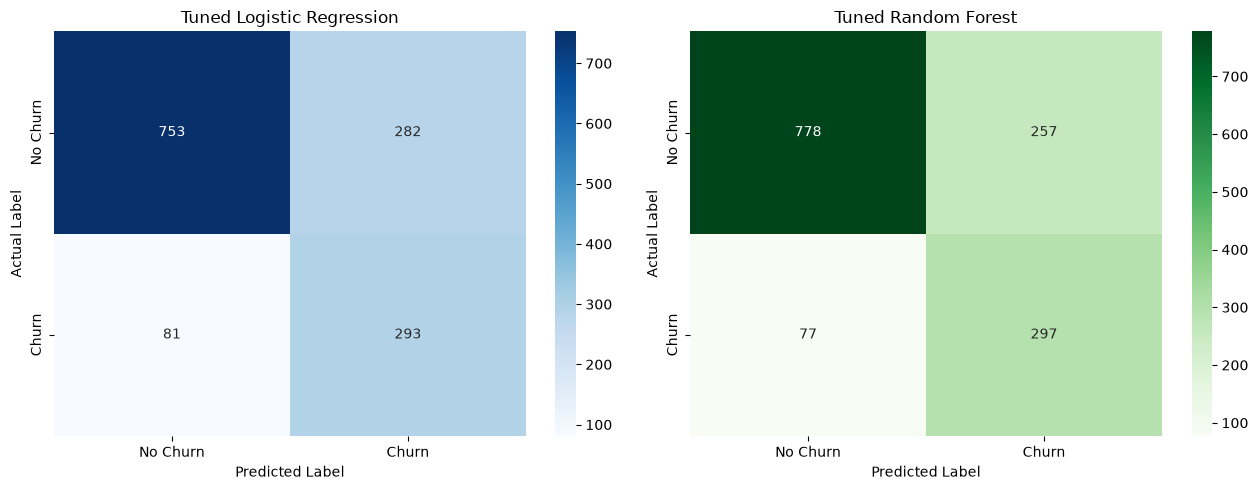

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrices
cm_log = confusion_matrix(
    y_test, y_pred_log_tuned, labels=[0, 1]
)

cm_rf = confusion_matrix(
    y_test, y_pred_rf_tuned, labels=[0, 1]
)

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Logistic Regression
sns.heatmap(
    cm_log,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"],
    ax=axes[0]
)

axes[0].set_title("Tuned Logistic Regression")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

# Random Forest
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"],
    ax=axes[1]
)

axes[1].set_title("Tuned Random Forest")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

### Step 17: Confusion Matrix Interpretation – Tuned Models

In this step, we analyze the confusion matrix results of both tuned models to understand their prediction errors.

**Comparison of Confusion Matrix Results**

| Metric | Tuned Logistic Regression | Tuned Random Forest |
|:---|---:|---:|
| True Negative (TN) | 753 | 778 |
| False Positive (FP) | 282 | 257 |
| False Negative (FN) | 81 | 77 |
| True Positive (TP) | 293 | 297 |

**Key Observations:**

1. Random Forest correctly identified 297 churn customers, compared to 293 by Logistic Regression.
2. Random Forest missed 77 actual churn customers, while Logistic Regression missed 81.
3. Random Forest produced 257 false positives, compared to 282 by Logistic Regression.
4. Random Forest correctly identified more non-churning customers (778 vs. 753).

**Conclusion:**

Tuned Random Forest performed slightly better than Tuned Logistic Regression across all four confusion matrix outcomes.

It identified more actual churn customers while producing fewer false positives and false negatives.

Therefore, Tuned Random Forest is currently our leading model for customer churn prediction.

### Step 18: Final Model Performance Comparison

In this step, we compare all five model configurations using their performance on the unseen test dataset.

**Models Compared:**
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Tuned Logistic Regression
5. Tuned Random Forest

**Evaluation Metrics:**
- Accuracy
- Churn Precision
- Churn Recall
- Churn F1-score

The primary objective is to identify the best-performing model for customer churn prediction.

We give particular importance to Churn Recall and Churn F1-score because identifying customers who are likely to leave is the main business objective.

In [53]:
import pandas as pd

# Compare all five model configurations
comparison_data = {
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Tuned Logistic Regression",
        "Tuned Random Forest"
    ],

    "Accuracy": [
        accuracy,
        accuracy_dt,
        accuracy_rf,
        accuracy_score(y_test, y_pred_log_tuned),
        accuracy_score(y_test, y_pred_rf_tuned)
    ],

    "Churn Precision": [
        0.66, 0.48, 0.62, 0.51, 0.54
    ],

    "Churn Recall": [
        0.56, 0.48, 0.49, 0.78, 0.79
    ],

    "Churn F1-score": [
        0.61, 0.48, 0.55, 0.62, 0.64
    ]
}

comparison_df = pd.DataFrame(comparison_data)

# Display comparison table
display(
    comparison_df.style.format({
        "Accuracy": "{:.2%}",
        "Churn Precision": "{:.2%}",
        "Churn Recall": "{:.2%}",
        "Churn F1-score": "{:.2%}"
    })
)

,Model,Accuracy,Churn Precision,Churn Recall,Churn F1-score
0,Logistic Regression,80.70%,66.00%,56.00%,61.00%
1,Decision Tree,72.53%,48.00%,48.00%,48.00%
2,Random Forest,78.50%,62.00%,49.00%,55.00%
3,Tuned Logistic Regression,74.24%,51.00%,78.00%,62.00%
4,Tuned Random Forest,76.30%,54.00%,79.00%,64.00%


### Final Model Comparison – Key Findings

After evaluating all five model configurations, the following observations were made:

1. Logistic Regression achieved the highest overall accuracy of 80.70%.
2. Tuned Random Forest achieved the highest Churn Recall of 79%.
3. Tuned Random Forest also achieved the highest Churn F1-score of 64%.
4. Hyperparameter tuning significantly improved churn detection for both Logistic Regression and Random Forest.

**Current Best Model: Tuned Random Forest**

Tuned Random Forest is selected as the current leading model because identifying customers who are likely to churn is the primary objective of this project.

The final selection will also consider feature importance and business requirements.

### Step 19: Feature Importance Analysis – Random Forest

Feature Importance helps us identify which input features contribute most to the predictions made by the Random Forest model.

In this step, we will:

- Extract feature importance scores from the tuned Random Forest model.
- Rank features according to their importance.
- Visualize the top 15 most influential features.

This analysis helps us understand the factors that contribute to customer churn prediction.

In [54]:
# Extract feature importance from tuned Random Forest

feature_importance = pd.DataFrame({
    "Feature": X_train_processed.columns,
    "Importance": best_rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
display(feature_importance.head(15))

,Feature,Importance
1,tenure,0.169801
3,TotalCharges,0.142761
25,Contract_Two year,0.112973
2,MonthlyCharges,0.098279
10,InternetService_Fiber optic,0.066539
28,PaymentMethod_Electronic check,0.053015
24,Contract_One year,0.042754
13,OnlineSecurity_Yes,0.035990
19,TechSupport_Yes,0.024821
18,TechSupport_No internet service,0.019777


### Step 19: Feature Importance Analysis – Random Forest

Feature Importance helps us identify which input features contribute most to the predictions made by the Random Forest model.

In this step, we will:

- Extract feature importance scores from the tuned Random Forest model.
- Rank features according to their importance.
- Visualize the top 15 most influential features.

This analysis helps us understand the factors that contribute to customer churn prediction.

In [55]:
# Extract feature importance from tuned Random Forest

feature_importance = pd.DataFrame({
    "Feature": X_train_processed.columns,
    "Importance": best_rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
display(feature_importance.head(15))

,Feature,Importance
1,tenure,0.169801
3,TotalCharges,0.142761
25,Contract_Two year,0.112973
2,MonthlyCharges,0.098279
10,InternetService_Fiber optic,0.066539
28,PaymentMethod_Electronic check,0.053015
24,Contract_One year,0.042754
13,OnlineSecurity_Yes,0.035990
19,TechSupport_Yes,0.024821
18,TechSupport_No internet service,0.019777


### Step 20: Feature Importance Visualization

In this step, we visualize the top 15 most important features identified by the tuned Random Forest model.

A horizontal bar chart will help us understand which customer attributes contribute most to the model's predictions.

This visualization provides insights into the factors that influence customer churn prediction.

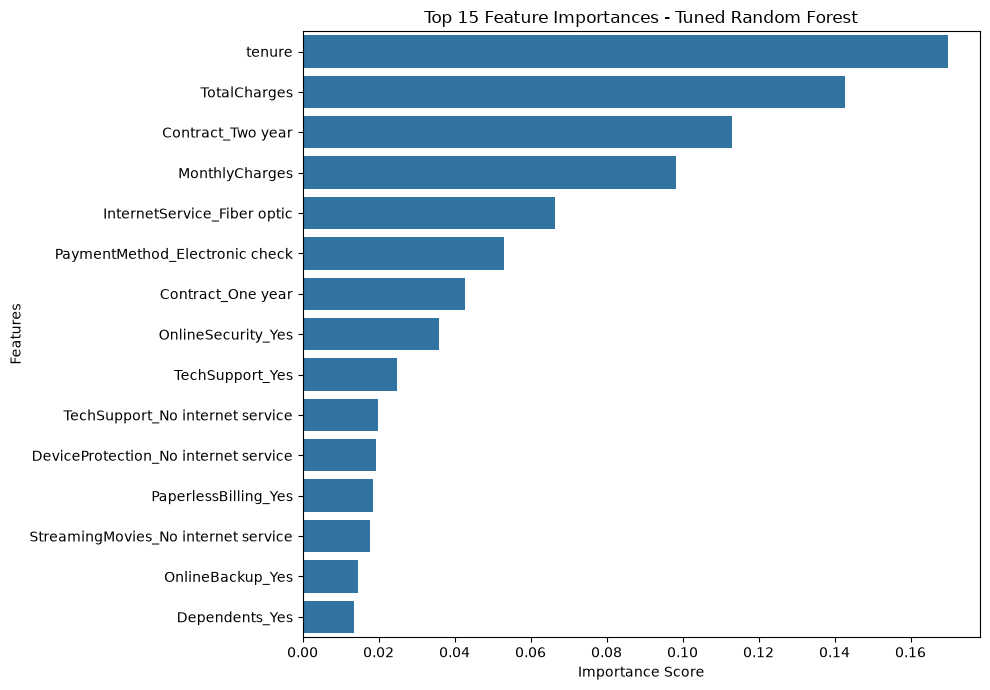

In [56]:
# Select top 15 important features
top_features = feature_importance.head(15)

# Create horizontal bar chart
plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importances - Tuned Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

### Step 20: Feature Importance Visualization

In this step, we visualize the top 15 most important features identified by the tuned Random Forest model.

A horizontal bar chart will help us understand which customer attributes contribute most to the model's predictions.

This visualization provides insights into the factors that influence customer churn prediction.

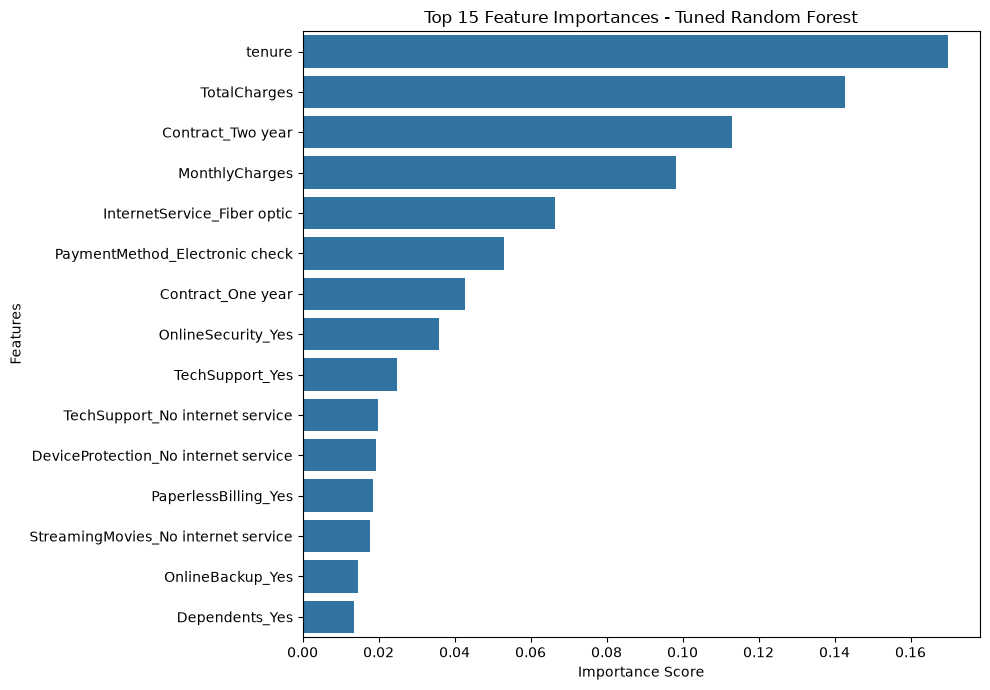

In [57]:
# Select top 15 important features
top_features = feature_importance.head(15)

# Create horizontal bar chart
plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importances - Tuned Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

### Step 21: Feature Importance Analysis – Key Observations

The Feature Importance visualization highlights the most influential features used by the Random Forest model.

**Key Observations:**

1. **Tenure:** The most important feature, indicating that customer relationship duration plays a major role in churn prediction.
2. **TotalCharges:** Customer spending history is another important factor.
3. **Contract Type:** Customers with two-year contracts contribute significantly to the model's predictions.
4. **MonthlyCharges:** Monthly billing amount also influences churn predictions.
5. **Internet Service:** Fiber optic service is among the important categorical features.

**Conclusion:**

Customer tenure, billing information, and contract type are among the most influential features in predicting customer churn.

*Note: Feature importance indicates predictive contribution, not causation or whether a feature increases or decreases churn.*

### Step 21: Final Model Selection

After evaluating and tuning different classification models, we compare their performance to select the final model.

**Final Model Comparison:**

| Evaluation Metric | Tuned Logistic Regression | Tuned Random Forest |
|---|---:|---:|
| Accuracy | 74.24% | 76.30% |
| Churn Precision | 51% | 54% |
| Churn Recall | 78% | 79% |
| Churn F1-score | 62% | 64% |

**Selected Model: Tuned Random Forest**

**Reasons for Selection:**

1. Achieved higher accuracy (76.30%).
2. Achieved higher churn precision (54%).
3. Achieved higher churn recall (79%).
4. Achieved the highest churn F1-score (64%).

**Conclusion:**

Tuned Random Forest is selected as the final model because it provides the best overall performance among the evaluated models, particularly in identifying customers who are likely to churn.

In [58]:
# Select the best Random Forest model
final_model = rf_grid.best_estimator_

print("Final Model Selected: Tuned Random Forest")

Final Model Selected: Tuned Random Forest


### Step 22: Final Model Evaluation

In this step, we evaluate the selected Tuned Random Forest model on the unseen testing dataset.

We will calculate:

1. Accuracy – Overall prediction correctness.
2. Precision – How many predicted churn customers actually churned.
3. Recall – How many actual churn customers were correctly identified.
4. F1-score – Balance between Precision and Recall.

This evaluation helps us understand how well our final model performs on unseen customer data.

In [59]:
from sklearn.metrics import accuracy_score, classification_report

# Generate predictions using the final model
y_pred_final = final_model.predict(X_test_processed)

# Calculate final accuracy
final_accuracy = accuracy_score(y_test, y_pred_final)

print("Final Model: Tuned Random Forest")
print("Final Accuracy:", round(final_accuracy * 100, 2), "%")

# Display classification report
print("\nFinal Classification Report:")
print(classification_report(
    y_test,
    y_pred_final,
    target_names=["No Churn", "Churn"]
))

Final Model: Tuned Random Forest
Final Accuracy: 76.3 %

Final Classification Report:
              precision    recall  f1-score   support

    No Churn       0.91      0.75      0.82      1035
       Churn       0.54      0.79      0.64       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409



### Step 23: Final Confusion Matrix

A confusion matrix provides a detailed breakdown of the final model's predictions.

It helps us identify:

- True Negatives (TN): Correctly predicted No Churn customers.
- False Positives (FP): No Churn customers incorrectly predicted as Churn.
- False Negatives (FN): Churn customers incorrectly predicted as No Churn.
- True Positives (TP): Correctly predicted Churn customers.

This visualization helps us understand the prediction errors made by our final Tuned Random Forest model.

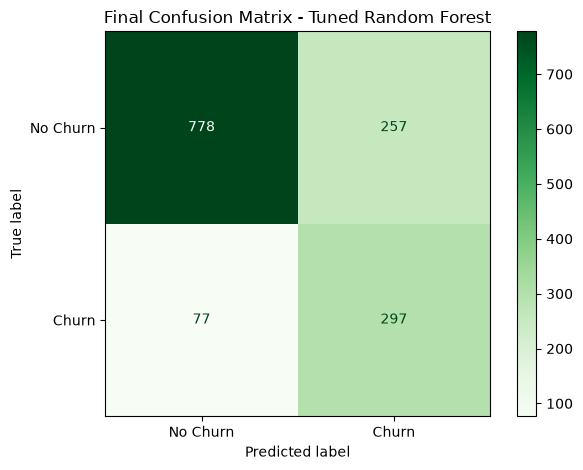

In [60]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm_final = confusion_matrix(y_test, y_pred_final)

# Visualize confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Greens", values_format="d")

plt.title("Final Confusion Matrix - Tuned Random Forest")
plt.tight_layout()
plt.show()

### Step 24: Save the Final Model

In this step, we save the trained Tuned Random Forest model using Joblib.

Saving the model allows us to reuse it later without retraining it from scratch.

We will save the model as `customer_churn_model.pkl`.

In [61]:
import joblib

# Save the final trained model
joblib.dump(final_model, "customer_churn_model.pkl")

print("Final model saved successfully!")

Final model saved successfully!


### Step 25: Save Preprocessing Objects

Along with the trained model, we also need to save the preprocessing objects used during training.

We will save:

1. StandardScaler – To scale numerical features.
2. OneHotEncoder – To encode categorical features.

Saving these objects ensures that future customer data receives the same transformations used during model training.

In [62]:
# Save preprocessing objects

joblib.dump(scaler, "scaler.pkl")
joblib.dump(encoder, "encoder.pkl")

print("Preprocessing objects saved successfully!")

Preprocessing objects saved successfully!


### Step 26: Verify Saved Model and Preprocessing Objects

In this step, we verify that the trained model and preprocessing objects have been saved correctly.

We will load all three files using Joblib to ensure they can be reused for future predictions without retraining.

In [63]:
# Load saved model and preprocessing objects

loaded_model = joblib.load("customer_churn_model.pkl")
loaded_scaler = joblib.load("scaler.pkl")
loaded_encoder = joblib.load("encoder.pkl")

print("Model and preprocessing objects loaded successfully!")

Model and preprocessing objects loaded successfully!


In [64]:
# Check saved preprocessing objects

print("Encoder Features:")
print(loaded_encoder.feature_names_in_)

print("\nScaler Features:")
print(loaded_scaler.feature_names_in_)

print("\nModel Expected Features:")
print(loaded_model.n_features_in_)

print("\nTraining Data Shape:")
print(X_train_processed.shape)

Encoder Features:
['gender' 'Partner' 'Dependents' 'PhoneService' 'MultipleLines'
 'InternetService' 'OnlineSecurity' 'OnlineBackup' 'DeviceProtection'
 'TechSupport' 'StreamingTV' 'StreamingMovies' 'Contract'
 'PaperlessBilling' 'PaymentMethod']

Scaler Features:
['SeniorCitizen' 'tenure' 'MonthlyCharges' 'TotalCharges']

Model Expected Features:
30

Training Data Shape:
(5634, 30)


In [65]:
# Create sample customer data

new_customer = pd.DataFrame({
    "gender": ["Female"],
    "SeniorCitizen": [0],
    "Partner": ["Yes"],
    "Dependents": ["No"],
    "tenure": [5],
    "PhoneService": ["Yes"],
    "MultipleLines": ["No"],
    "InternetService": ["Fiber optic"],
    "OnlineSecurity": ["No"],
    "OnlineBackup": ["No"],
    "DeviceProtection": ["No"],
    "TechSupport": ["No"],
    "StreamingTV": ["No"],
    "StreamingMovies": ["No"],
    "Contract": ["Month-to-month"],
    "PaperlessBilling": ["Yes"],
    "PaymentMethod": ["Electronic check"],
    "MonthlyCharges": [75.50],
    "TotalCharges": [377.50]
})

display(new_customer)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,5,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,75.5,377.5


In [66]:
# Separate categorical and numerical features

categorical_data = new_customer[loaded_encoder.feature_names_in_]
numerical_data = new_customer[loaded_scaler.feature_names_in_]

# Apply OneHotEncoder
encoded_data = loaded_encoder.transform(categorical_data)

encoded_df = pd.DataFrame(
    encoded_data,
    columns=loaded_encoder.get_feature_names_out(),
    index=new_customer.index
)

# Apply StandardScaler
scaled_data = loaded_scaler.transform(numerical_data)

scaled_df = pd.DataFrame(
    scaled_data,
    columns=loaded_scaler.feature_names_in_,
    index=new_customer.index
)

# Combine processed features
processed_customer = pd.concat(
    [scaled_df, encoded_df],
    axis=1
)

# Match the exact feature order used during model training
feature_order = (
    loaded_model.feature_names_in_
    if hasattr(loaded_model, "feature_names_in_")
    else X_train_processed.columns
)

processed_customer = processed_customer.reindex(
    columns=feature_order
)

print("Customer preprocessing completed!")
print("Processed Shape:", processed_customer.shape)

Customer preprocessing completed!
Processed Shape: (1, 30)


In [67]:
# Predict customer churn

prediction = loaded_model.predict(processed_customer)

# Calculate churn probability
probabilities = loaded_model.predict_proba(processed_customer)

churn_probability = probabilities[0][
    list(loaded_model.classes_).index(1)
]

# Display prediction result
if prediction[0] == 1:
    print("Prediction: Customer Will Churn")
else:
    print("Prediction: Customer Will Not Churn")

print("Churn Probability:", round(churn_probability * 100, 2), "%")

Prediction: Customer Will Churn
Churn Probability: 84.2 %
